# CICIDS2017 supervised intrusion-detection experiments

## tl;dr

This notebook is the executed, reviewable companion to the thesis. It loads the generated evidence rather than retraining models during ordinary review. Use `python -m src.nids_experiment` to reproduce the full pipeline from the official CSV files.

## Context & Methods

The study compares Logistic Regression, linear Support Vector Machine, and Random Forest under three conditions: a stratified binary holdout, multiclass attack-category classification, and a Friday-only day-shift test. A dummy classifier anchors the binary comparison. All preprocessing is fitted on training data, exact sampled duplicates are removed before splitting, and all rare-class rows are retained when valid.

### Key assumptions

- CICIDS2017 is a controlled benchmark and does not represent every operational network.
- Random row splits can reward day-specific benchmark regularities, so the day-shift test is interpreted alongside the main holdout.
- Very small classes have unstable per-class estimates. Support counts must be read with their scores.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TABLES = ROOT / "outputs" / "tables"
FIGURES = ROOT / "outputs" / "figures"

profile = json.loads((TABLES / "dataset_profile.json").read_text(encoding="utf-8"))
design = json.loads((TABLES / "experiment_design.json").read_text(encoding="utf-8"))
binary = pd.read_csv(TABLES / "binary_model_metrics.csv")
multiclass = pd.read_csv(TABLES / "multiclass_model_metrics.csv")
day_shift = pd.read_csv(TABLES / "day_shift_binary_metrics.csv")
validation = json.loads((TABLES / "validation_checks.json").read_text(encoding="utf-8"))

## Data

In [2]:
pd.DataFrame({
    "Measure": [
        "Raw flows", "Invalid rows removed", "Sampled duplicates removed",
        "Clean sampled flows", "Features", "Multiclass sample rows"
    ],
    "Value": [
        profile["raw_rows"], profile["invalid_rows_removed"],
        profile["duplicate_sample_rows_removed"], profile["sample_rows_after_deduplication"],
        design.get("feature_count", 78), design["multiclass_rows"]
    ]
})

,Measure,Value
0,Raw flows,2830743
1,Invalid rows removed,2867
2,Sampled duplicates removed,38168
3,Clean sampled flows,527910
4,Features,78
5,Multiclass sample rows,37676


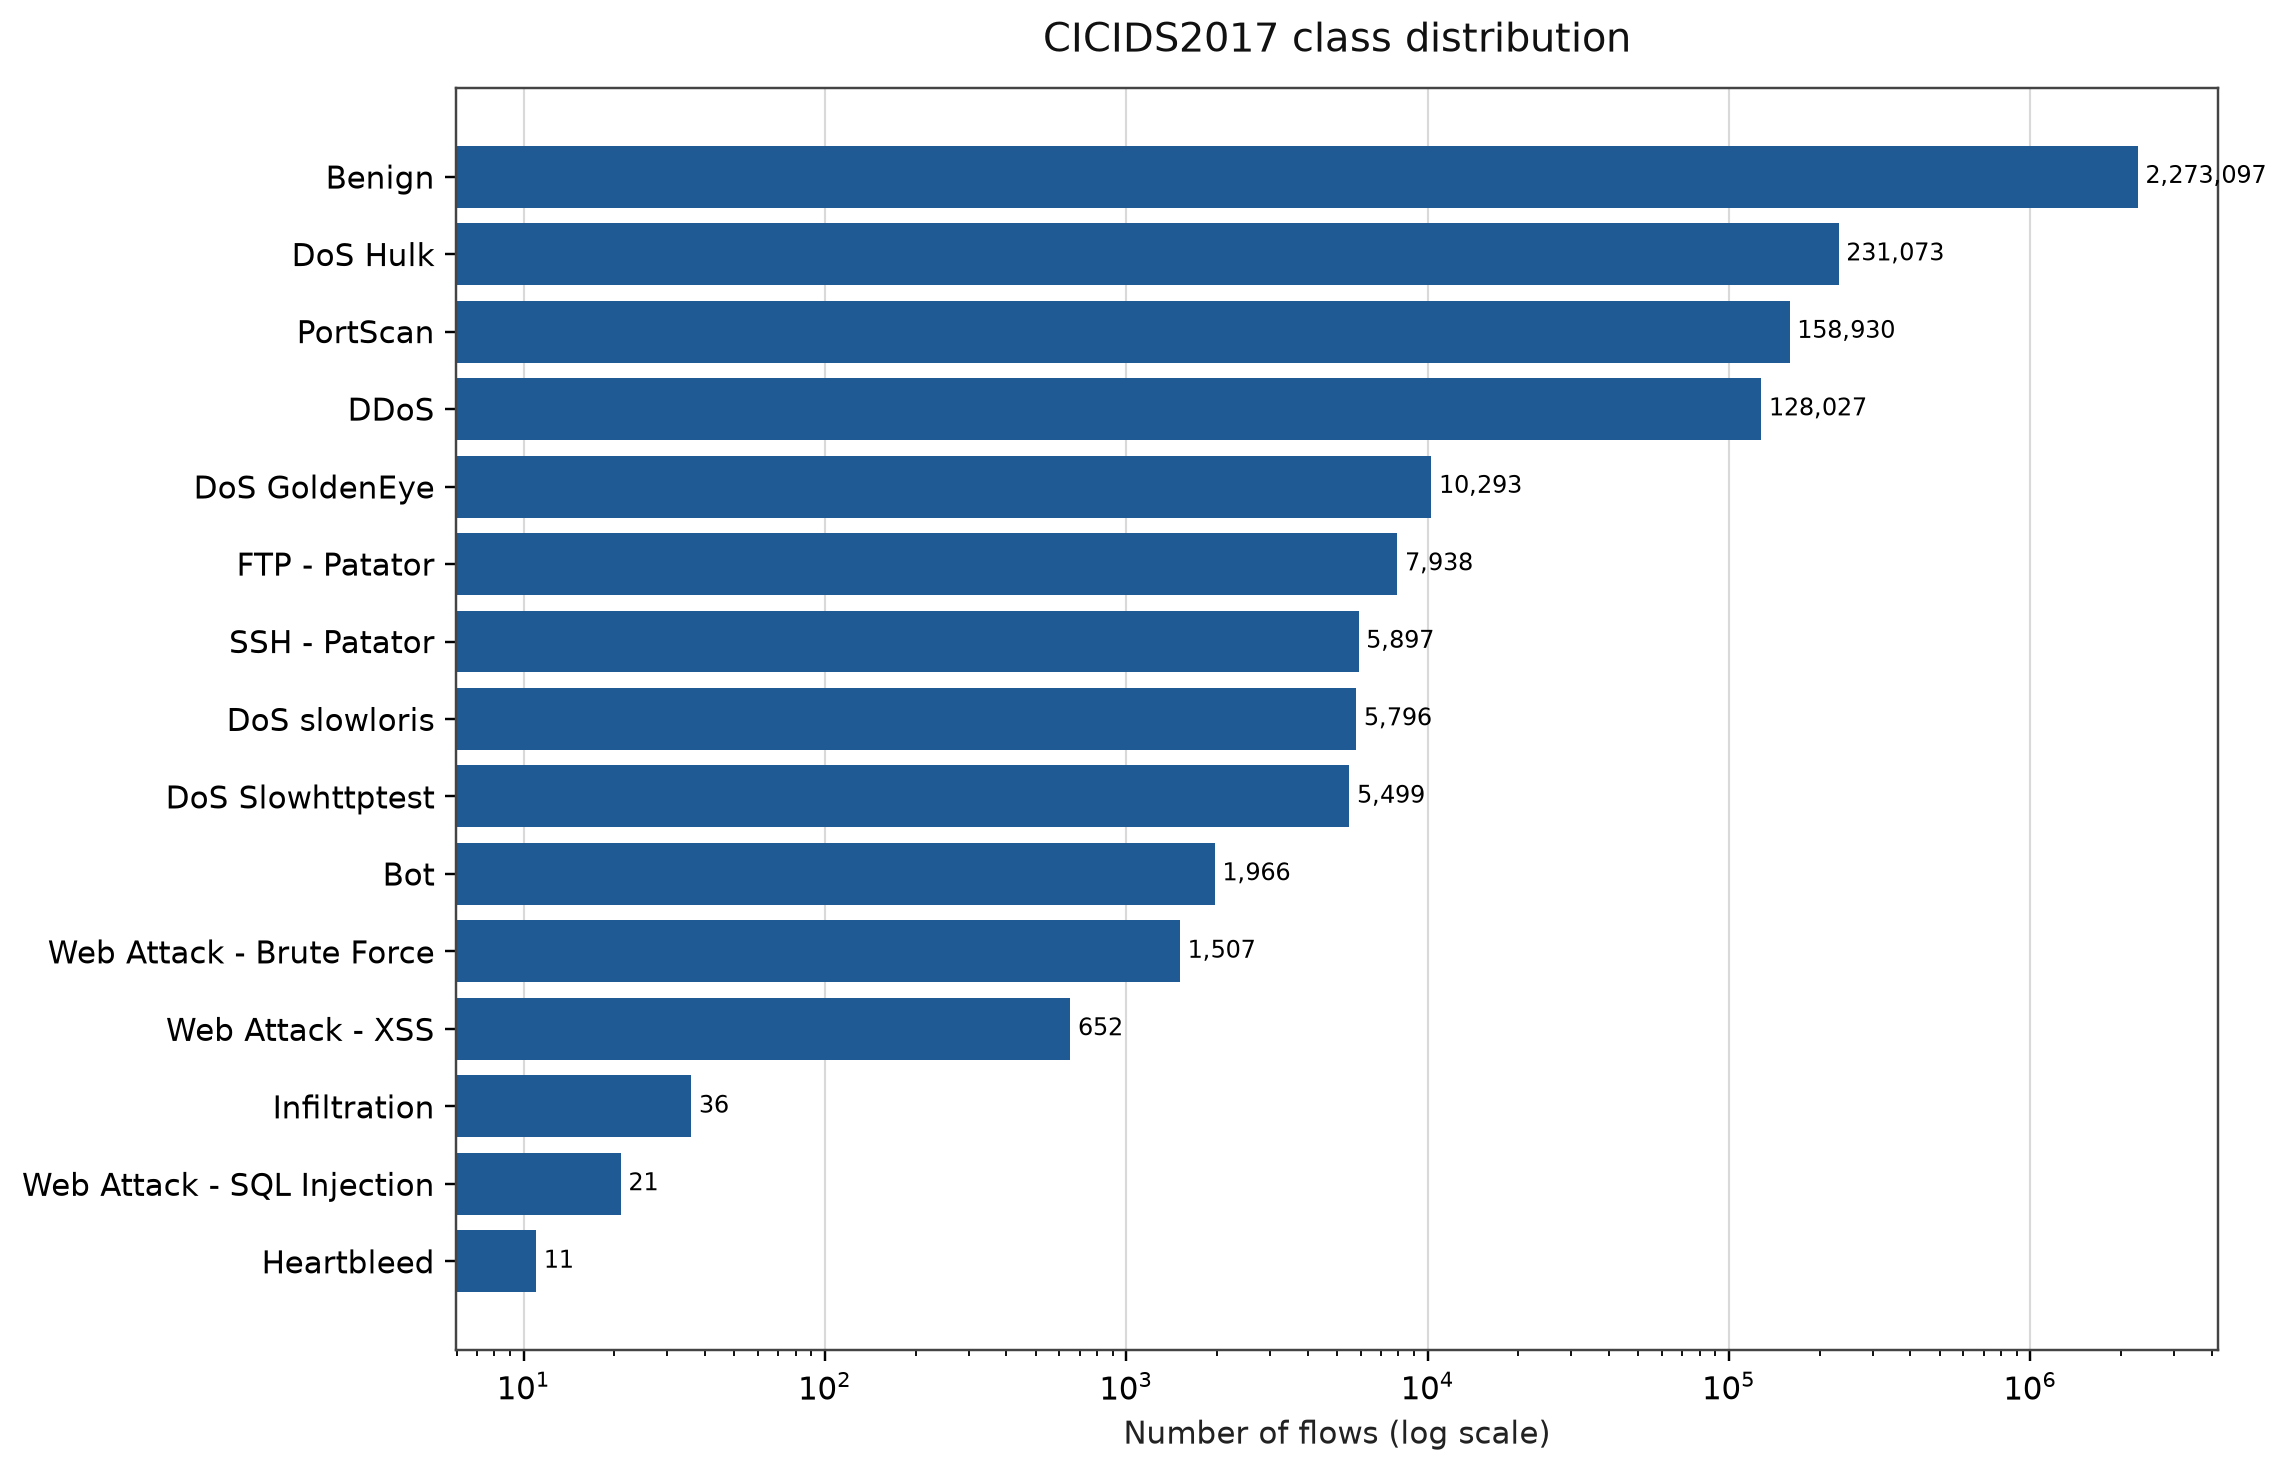

In [3]:
display(Image(filename=str(FIGURES / 'class_distribution_full.png'), width=900))

The logarithmic axis reveals the class imbalance that an overall accuracy figure would conceal. Heartbleed, SQL injection, and Infiltration have fewer than 40 raw records each.

## Results

In [4]:
binary[["model", "accuracy", "balanced_accuracy", "precision", "recall", "f1",
        "false_positive_rate", "false_negative_rate", "mcc", "roc_auc"]].round(4)

,model,accuracy,balanced_accuracy,precision,recall,f1,false_positive_rate,false_negative_rate,mcc,roc_auc
0,Dummy,0.8195,0.5000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.5000
1,Logistic Regression,0.8747,0.9091,0.5945,0.9629,0.7351,0.1447,0.0371,0.6918,0.9711
2,Linear SVM,0.9211,0.9369,0.7069,0.9616,0.8148,0.0879,0.0384,0.7808,0.9820
3,Random Forest,0.9988,0.9982,0.9959,0.9973,0.9966,0.0009,0.0027,0.9958,0.9999
4,Logistic Regression (unweighted),0.9066,0.7533,0.9431,0.5134,0.6648,0.0068,0.4866,0.6545,0.9688


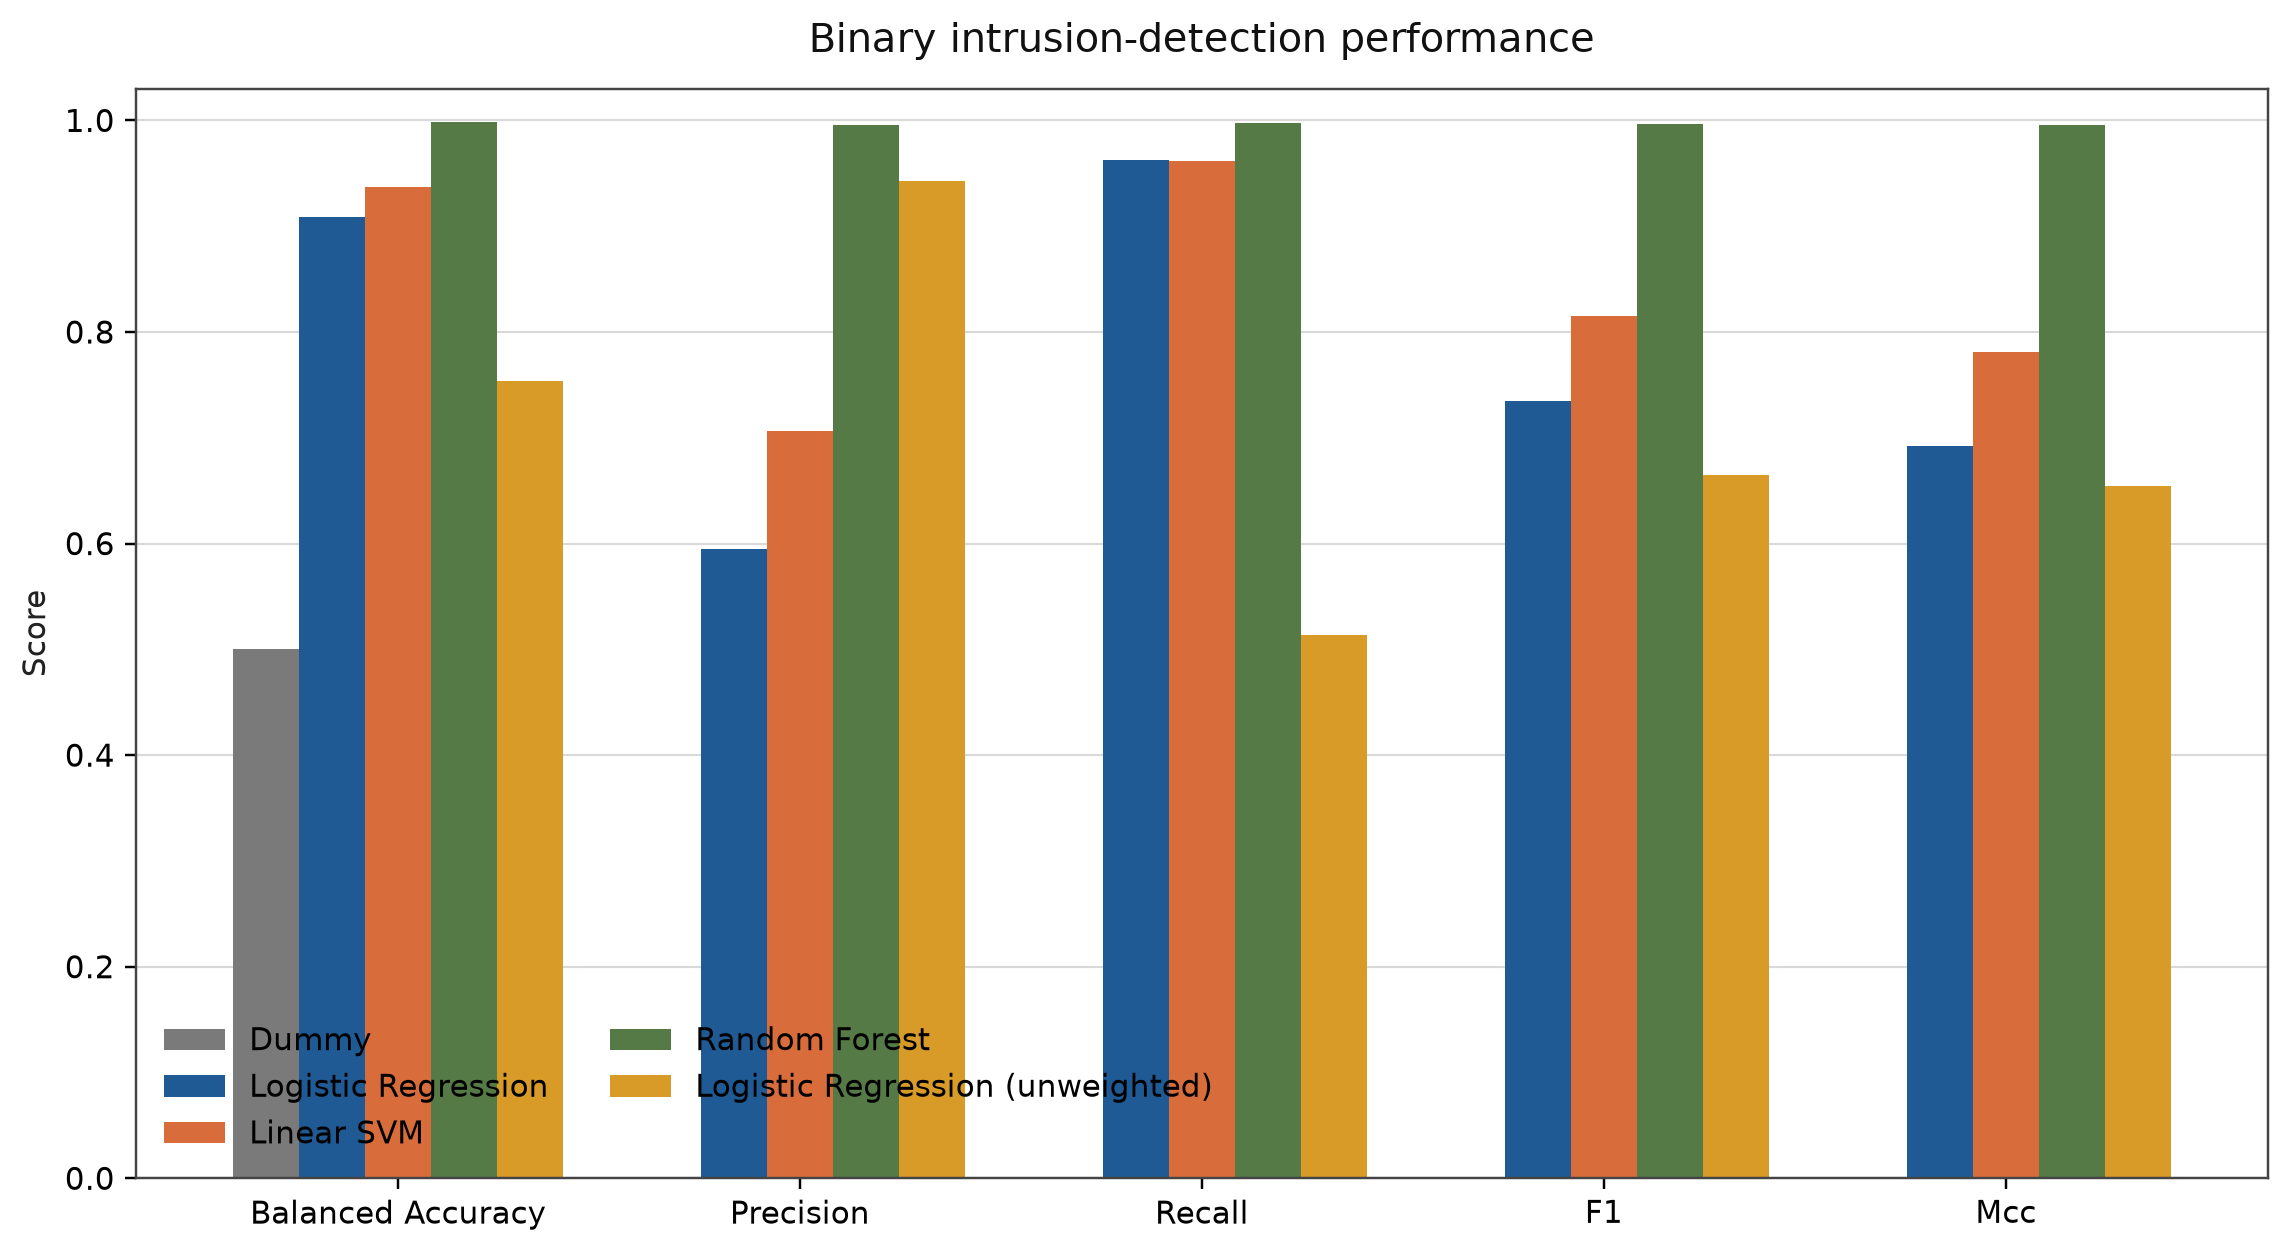

In [5]:
display(Image(filename=str(FIGURES / 'binary_model_comparison.png'), width=950))

Random Forest performs best on the stratified random holdout. The dummy baseline's high accuracy and zero attack recall show why class-aware metrics are required. Weighting Logistic Regression increases attack recall substantially, at the cost of more false positives.

In [6]:
multiclass[["model", "accuracy", "balanced_accuracy", "macro_precision", "macro_recall",
            "macro_f1", "weighted_f1", "mcc"]].round(4)

,model,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,mcc
0,Logistic Regression,0.8697,0.7968,0.6634,0.7968,0.6793,0.8798,0.8499
1,Linear SVM,0.9326,0.8119,0.7029,0.8119,0.7061,0.9345,0.9207
2,Random Forest,0.9854,0.8925,0.9236,0.8925,0.8987,0.9852,0.9825


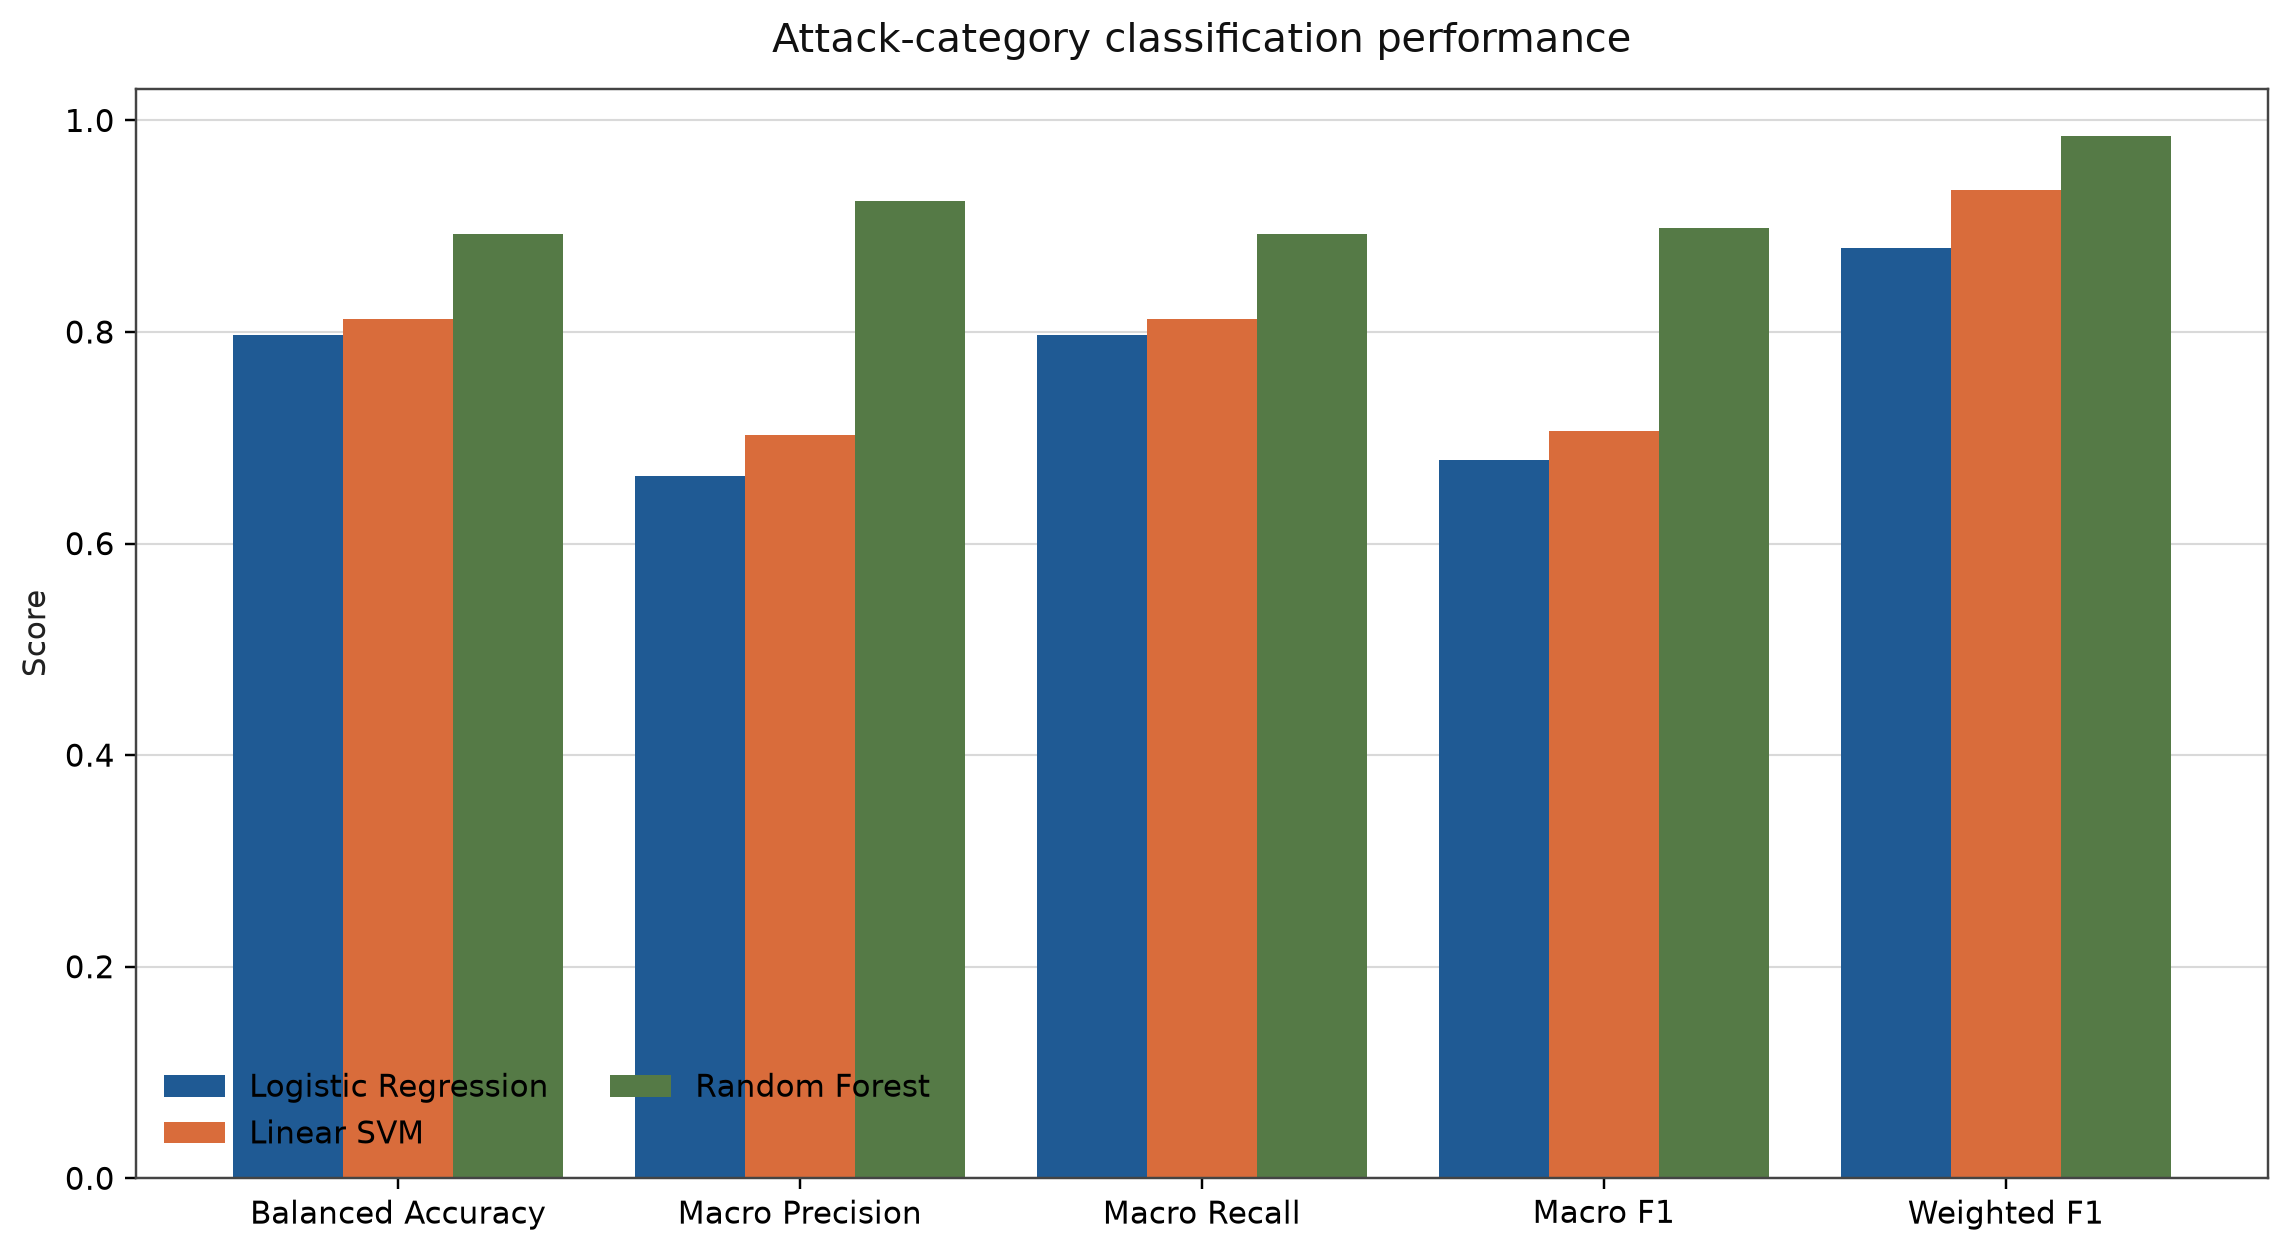

In [7]:
display(Image(filename=str(FIGURES / 'multiclass_model_comparison.png'), width=950))

Macro scores remain below weighted scores because rare categories are harder to classify. Random Forest leads, but estimates for classes with only a few test examples remain uncertain.

In [8]:
day_shift[["model", "accuracy", "balanced_accuracy", "precision", "recall", "f1",
           "false_positive_rate", "false_negative_rate", "mcc", "roc_auc"]].round(4)

,model,accuracy,balanced_accuracy,precision,recall,f1,false_positive_rate,false_negative_rate,mcc,roc_auc
0,Dummy,0.6045,0.5000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.5000
1,Logistic Regression,0.7528,0.6941,0.9153,0.4132,0.5693,0.0250,0.5868,0.4956,0.8505
2,Linear SVM,0.7610,0.7169,0.8215,0.5056,0.6260,0.0719,0.4944,0.4942,0.8448
3,Random Forest,0.7266,0.6545,0.9965,0.3097,0.4726,0.0007,0.6903,0.4602,0.8161


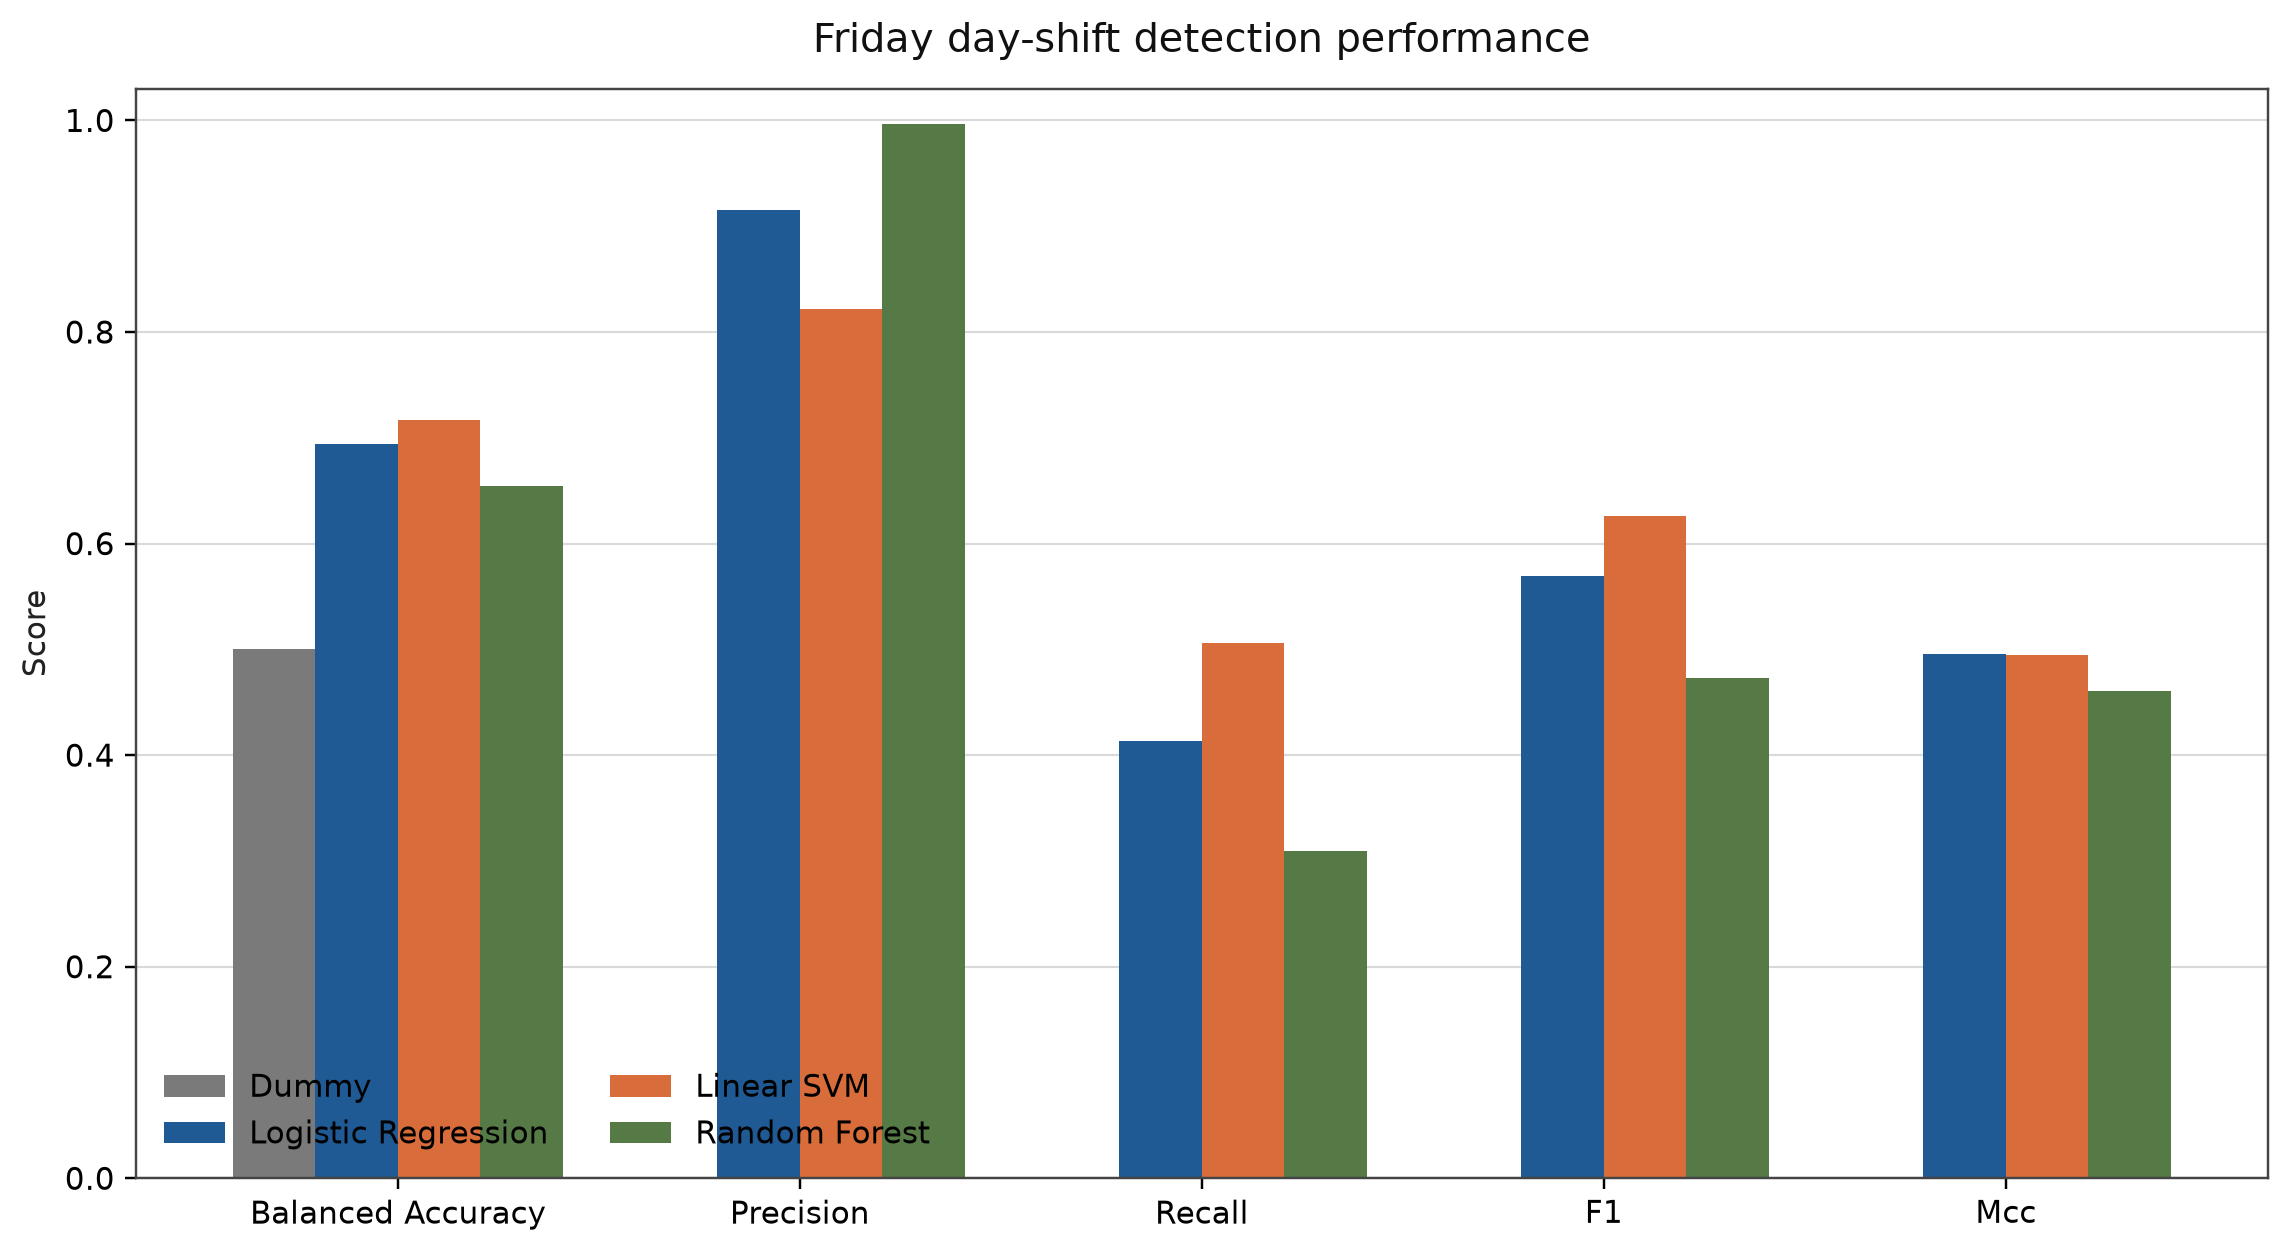

In [9]:
display(Image(filename=str(FIGURES / 'day_shift_model_comparison.png'), width=950))

All learned models lose attack recall on Friday-only traffic. The decline is largest for Random Forest, which supports a cautious interpretation of its near-perfect random-split performance.

## Takeaways

In [10]:
summary = {
    "Random-split best macro/binary model": binary.loc[binary["f1"].idxmax(), "model"],
    "Random Forest random-split attack recall": float(binary.loc[binary["model"] == "Random Forest", "recall"].iloc[0]),
    "Random Forest Friday attack recall": float(day_shift.loc[day_shift["model"] == "Random Forest", "recall"].iloc[0]),
    "Best multiclass macro F1": float(multiclass["macro_f1"].max()),
    "Independent validation passed": validation["all_checks_pass"],
}
pd.Series(summary, name="Observed value")

Random-split best macro/binary model        Random Forest
Random Forest random-split attack recall         0.997272
Random Forest Friday attack recall               0.309732
Best multiclass macro F1                         0.898663
Independent validation passed                        True
Name: Observed value, dtype: object

The benchmark supports Random Forest as the strongest model under the defined random-split conditions. The day-shift results show that this ranking does not establish operational generalization. Future work should test later datasets, group-aware or temporal splits, calibrated thresholds, and feature sets designed for cross-network comparability.